# How-To: Multiple Source-Target Connections

| | |
|---|---|
| **Previous** | [How-To: Empirical Reliability](howto_empirical_reliability.ipynb) |
| **Prerequisite** | Notebooks 1 & 2 (MTBF / MTTR basics) |

Every example so far analysed a **single** connection (Alice → Bob).
Real ICT systems often require **multiple** communication links to be
operational simultaneously — for example:

* A SCADA system where **all** RTUs must reach the control centre.
* A redundant control setup where **at least one** of two backup links works.
* A distributed system requiring **k-out-of-n** services.

The `min_connected` parameter controls the requirement:

```

## min_connected = -1  →  ALL connections must work   (AND)

## min_connected =  1  →  ANY one connection suffices  (OR)

## min_connected =  k  →  at least k of n must work   (k-out-of-n)

```

In [1]:
import pandaict as pi
from pandaict.reliability.reliability import (
    estimate_mtbf_mttr_for_conn,
    analyze_critical_components_for_conn,
    empirical_reliability_function,
    plot_graph
)
from demo_networks import (
    simple_two_pair_net,
    four_path_net,
    two_source_shared_component_net,
)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

----
## Example 1 — Two Connections, All Required (default)

We start with two **fully independent** source-target pairs that share no
network components:

```

## Pair 1:  [Alice]   --- (NodeA) --- (NodeB) --- [Bob]

## Pair 2:  [Charlie] --- (NodeC) --- (NodeD) --- [Diana]

##

## Nodes: MTBF = 8 760 h, MTTR = 0 (non-repairable)

## Links: perfect

##
```

With `min_connected = -1` (default) the system is DOWN as soon as
**either** pair loses connectivity.

Each pair has MTTF $\approx$ 4 380 h.  Requiring **both** makes the system a
series composition of two independent sub-systems:

$$\text{MTTF}_{\text{all}} = \frac{1}{\lambda_1 + \lambda_2}
    = \frac{4\,380}{2} = 2\,190 \;\text{h}$$

In [2]:
net, sources, targets = simple_two_pair_net()

# Create one connection per pair
conns = [
    pi.create_ict_connection(net, name='', from_app=s, to_app=t, protocol="TCP")
    for s, t in zip(sources, targets)
]

result_all = estimate_mtbf_mttr_for_conn(
    net, conns, N=10_000_000, min_connected=-1
)

print(f"ALL required  (min_connected = -1)")
print(f"  MTTF = {result_all['mttf_h']:.2f} h   (expected ≈ 2 190 h)")

Running 10000000 simulations in parallel...
ALL required  (min_connected = -1)
  MTTF = 2190.07 h   (expected ≈ 2 190 h)


---
## Example 2 — Any-of-N (`min_connected = 1`)

Same network, but now the system is operational as long as **at least one**
pair is connected.  This turns the two independent sub-systems into a
parallel arrangement:

$$\text{MTTF}_{\text{any}}
    = \frac{1}{\lambda} + \frac{1}{2\lambda}
    = \frac{3}{2} \times 4\,380
    = 6\,570 \;\text{h}$$

In [3]:
result_any = estimate_mtbf_mttr_for_conn(
    net, conns, N=10_000_000, min_connected=1
)

print(f"ANY suffices  (min_connected = 1)")
print(f"  MTTF = {result_any['mttf_h']:.2f} h   (expected ≈ 6 570 h)")

# ── comparison ──
cmp = pd.DataFrame({
    "min_connected": ["-1 (all)", "1 (any)"],
    "MTTF (h)": [f"{result_all['mttf_h']:,.0f}",
                 f"{result_any['mttf_h']:,.0f}"],
    "vs. single pair": [
        f"{result_all['mttf_h']/4380:.2f}×",
        f"{result_any['mttf_h']/4380:.2f}×",
    ],
})
cmp

Running 10000000 simulations in parallel...
ANY suffices  (min_connected = 1)
  MTTF = 6567.92 h   (expected ≈ 6 570 h)


,min_connected,MTTF (h),vs. single pair
0,-1 (all),"2,190",0.50×
1,1 (any),"6,568",1.50×


Relaxing the requirement from ALL to ANY gives roughly a **3× MTTF
improvement** on this network — simply by accepting that *one* of the two
links may be down.

---
## Example 3 — k-out-of-n Sweep


----
## Example 1 — Two Connections, All Required (default)

We start with two **fully independent** source-target pairs that share no
network components:

```
## ===========================================================
## four_path_net

## 2 sources x 2 targets = 4 independent paths.
## In order to realize the 4 independent connections virtual devices have to be installed
## Demonstrates broadcasting: when sources and targets have
## different lengths, they are broadcast to match.

##              (Vdev1)---[NodeA]----[NodeB]----+
##             /                                 \
## [Source1]--+                                   +---[NodeC]---[Target1]
##            \                                  /
##              (Vdev2)---[NodeD]----[NodeE]----+

##               (Vdev3)---[NodeF]----[NodeG]---+
##               /                               \
##   [Source2]--+                                 +---[NodeH]---[Target2]
##               \                               /
##               (Vdev4)---[NodeI]----[NodeJ]---+

## Connections (broadcasting):
##   Vdev1 -> Target1
##   Vdev2 -> Target1
##   Vdev3 -> Target2
##   Vdev4 -> Target2
##
## []=dev, ()=node, {}=app
## ===========================================================
```

`four_path_net()` provides **four independent** source-target pairs.
We sweep `min_connected` from 1 (any) to all (−1) and observe how MTTF
degrades as the requirement becomes stricter.

For *n* independent, identically distributed exponential sub-systems the
MTTF when requiring at least *k* is the **(n − k + 1)**-th order-statistic
expectation:

$$\text{MTTF}(k,n) = \text{MTTF}_{\text{sub}} \;\sum_{i=0}^{n-k}
    \frac{1}{n - i}$$

In [4]:
net4, src4, tgt4 = four_path_net()
conns4 = [
    pi.create_ict_connection(net4, name='', from_app=s, to_app=t, protocol="TCP")
    for s, t in zip(src4, tgt4)
]

n_conns = len(conns4)
k_values = list(range(1, n_conns)) + [-1]   # [1, 2, 3, -1]
k_records = []

for k in k_values:
    r = estimate_mtbf_mttr_for_conn(net4, conns4, N=100_000, min_connected=k)
    k_records.append(dict(
        min_connected=str(k) if k != -1 else f"-1 (={n_conns})",
        k_eff=k if k != -1 else n_conns,
        mttf_h=r["mttf_h"],
    ))

df_k = pd.DataFrame(k_records)
df_k

Running 100000 simulations in parallel...
Running 100000 simulations in parallel...
Running 100000 simulations in parallel...
Running 100000 simulations in parallel...


,min_connected,k_eff,mttf_h
0,1,1,5852.122610
1,2,2,3213.899945
2,3,3,1748.929033
3,-1 (=4),4,880.465812


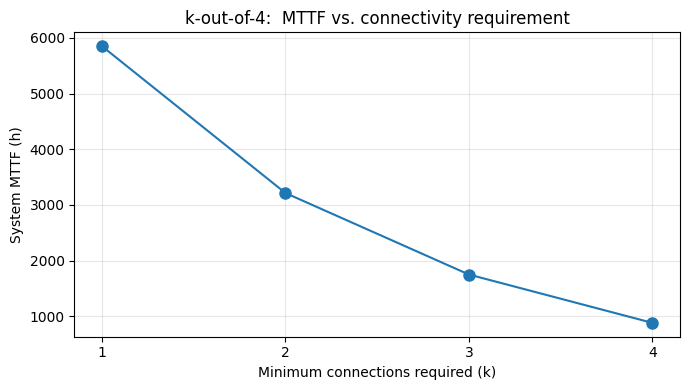

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_k["k_eff"], df_k["mttf_h"], "o-", markersize=8)
ax.set_xlabel("Minimum connections required (k)")
ax.set_ylabel("System MTTF (h)")
ax.set_title(f"k-out-of-{n_conns}:  MTTF vs. connectivity requirement")
ax.set_xticks(df_k["k_eff"])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The curve shows **graceful degradation**: each additional required
connection reduces the system MTTF.  Moving from *k = 1* to *k = n*
represents the full trade-off between fault tolerance and coverage.

---
## Example 4 — Shared Components Change Everything

So far all pairs were independent.  In real networks, paths often share
switches, routers, or cable ducts.

`two_source_shared_component_net()` creates **two pairs that share a
common component**.  When that component fails, **both** connections go
down simultaneously.

```

## [Alice]   --- (NodeA) --- +                  + --- (NodeB) --- [Bob]
                             |                  |
##                           + --- (Shared) --- +
                             |                  |
## [Charlie] --- (NodeC) --- +                   + --- (NodeD) --- [Diana]

## ```

  name  in_service  uuid  from  to protocol info_items peers producer prod_freq_ms
0             True  None     0   1      TCP       None  None     None         None
1             True  None     2   3      TCP       None  None     None         None


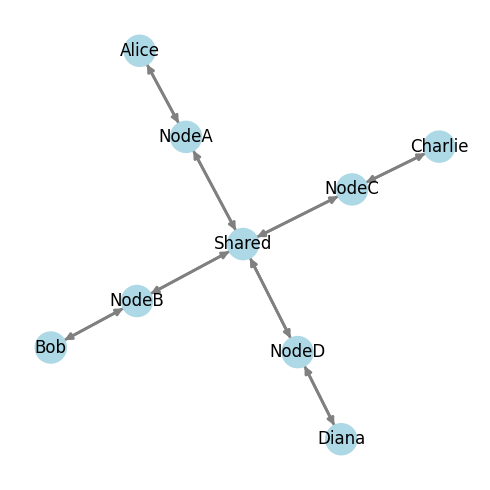

Running 100000 simulations in parallel...
Running 100000 simulations in parallel...


,min_connected,MTTF (h)
0,-1 (all),1743
1,1 (any),4107


In [6]:
net_sh, src_sh, tgt_sh = two_source_shared_component_net()
conns_sh = [
    pi.create_ict_connection(net_sh, name='', from_app=s, to_app=t, protocol="TCP")
    for s, t in zip(src_sh, tgt_sh)
]

print(net_sh.conn)

plot_graph(net_sh, seed=5)

r_sh_all = estimate_mtbf_mttr_for_conn(
    net_sh, conns_sh, N=100_000, min_connected=-1
)
r_sh_any = estimate_mtbf_mttr_for_conn(
    net_sh, conns_sh, N=100_000, min_connected=1
)

df_sh = pd.DataFrame({
    "min_connected": ["-1 (all)", "1 (any)"],
    "MTTF (h)": [f"{r_sh_all['mttf_h']:.0f}",
                 f"{r_sh_any['mttf_h']:.0f}"],
})
df_sh

Compare these numbers with the **independent** two-pair network from
Examples 1 & 2.  With shared components the benefit of `min_connected = 1`
is **much smaller** (or even zero if the shared component dominates), because
a single failure can knock out all connections at once.

> **Rule of thumb:** `min_connected = 1` helps most when each connection
> uses a truly *separate* path.  Shared bottlenecks undermine the
> redundancy.

---
## Example 5 — Finding the Bottleneck with Critical-Component Analysis

We can use `analyze_critical_components_for_conn` to **confirm** that the
shared node is the dominant bottleneck.

  min_connected = -1  (ALL required)
Running 100000 simulations in parallel...


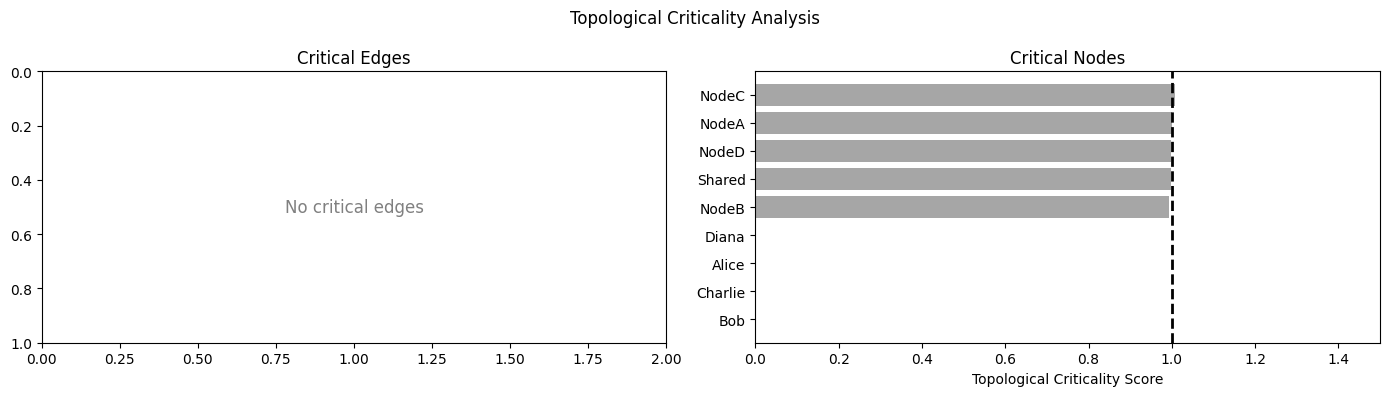

In [12]:
# ── with min_connected = -1 (all required) ──
print("=" * 60)
print("  min_connected = -1  (ALL required)")
print("=" * 60)
crit_all = analyze_critical_components_for_conn(
    net_sh, conns_sh,
    plot=True, verbose=False, rate_adjustment=True,
    N=100_000, min_connected=-1,
)

  min_connected = 1  (ANY suffices)
Running 100000 simulations in parallel...


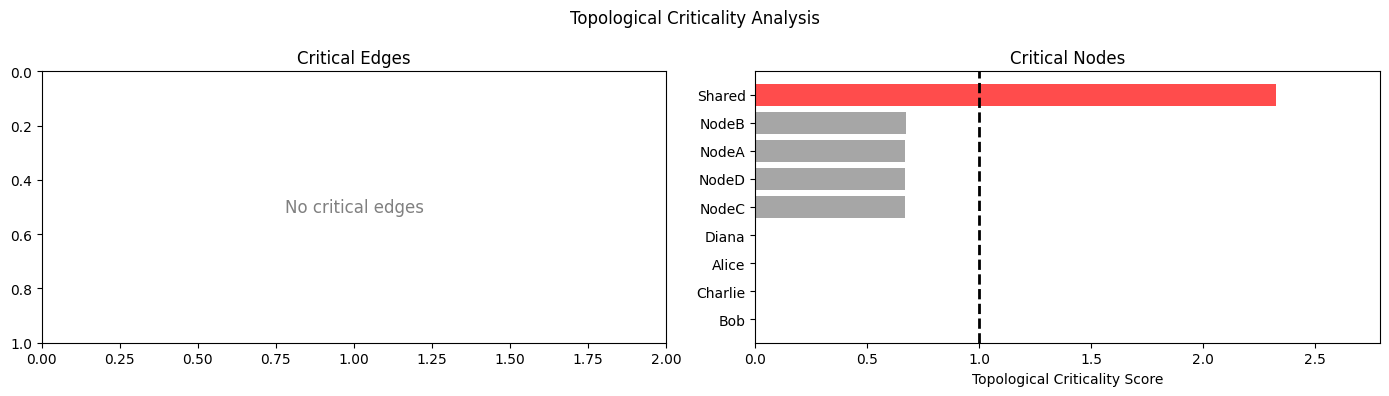

In [13]:
# ── with min_connected = 1 (any suffices) ──
print("=" * 60)
print("  min_connected = 1  (ANY suffices)")
print("=" * 60)
crit_any = analyze_critical_components_for_conn(
    net_sh, conns_sh,
    plot=True, verbose=False, rate_adjustment=True,
    N=100_000, min_connected=1,
)
plot_graph(

**Interpretation**

| Scenario | Observation |
|----------|-------------|
| `min_connected = -1` | Several nodes are critical because *any* single node failure breaks at least one connection. |
| `min_connected = 1` | **Only the shared node** dominates because it is the only single point of failure that takes down *all* connections simultaneously. |

This is a powerful diagnostic: combining `min_connected` with criticality
analysis tells you exactly **where** to invest in redundancy.

---
## Example 6 — Reliability Function R(T) with Different Requirements

Finally, let's visualise how the connectivity requirement shifts the
survival curve R(T) = P(system lifetime > T).

In [9]:
T = np.linspace(0, 15_000, 200)

# Back to the independent two-pair network for a clean comparison
R_all = empirical_reliability_function(
    net, conns, T, N=100_000, min_connected=-1
)
R_any = empirical_reliability_function(
    net, conns, T, N=100_000, min_connected=1
)

Running 100000 simulations in parallel...
Running 100000 simulations in parallel...


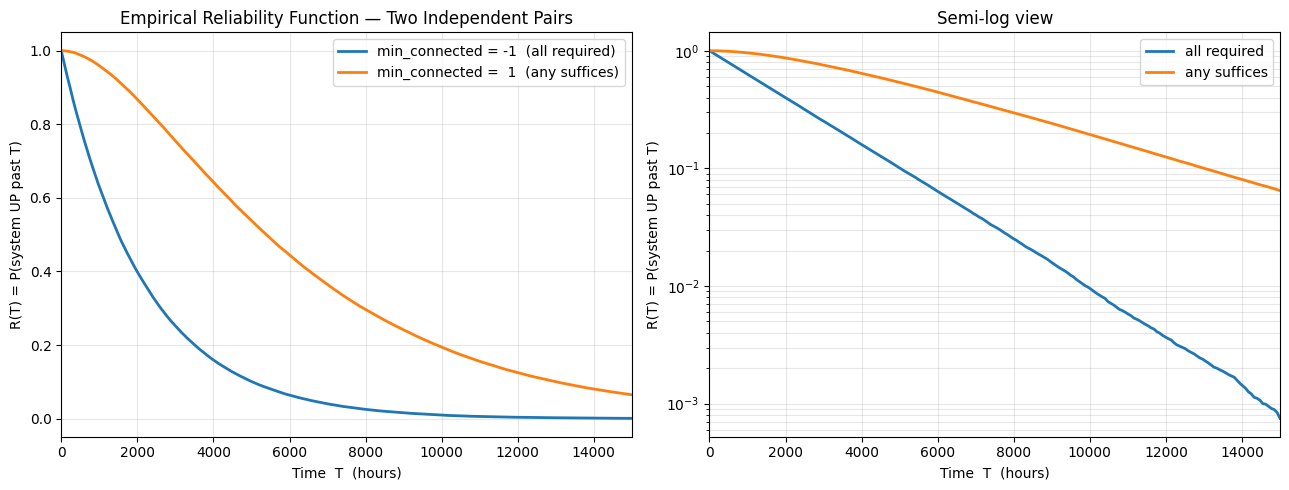

In [19]:
fig, axes = plt.subplots(figsize=(13, 5), ncols=2)
axes[0].plot(T, R_all, label="min_connected = -1  (all required)", lw=2)
axes[0].plot(T, R_any, label="min_connected =  1  (any suffices)", lw=2)
axes[0].set_title("Empirical Reliability Function — Two Independent Pairs")

axes[1].semilogy(T, R_all, label="all required", lw=2)
axes[1].semilogy(T, R_any, label="any suffices", lw=2)
axes[1].set_title("Semi-log view")

for ax in axes:
    ax.set_xlim(T.min(), T.max())
    ax.set_xlabel("Time  T  (hours)")
    ax.set_ylabel("R(T) = P(system UP past T)")
    ax.legend()
    ax.grid(True, alpha=0.3, which="both")
    
plt.tight_layout()
plt.show()

The curve for `min_connected = 1` is shifted far to the right — the system
survives much longer because it only needs *one* working connection.

On a semi-log scale the difference in slope reveals the different effective
failure rates.

---
## Summary

| `min_connected` | Semantics | Use case |
|-----------------|-----------|----------|
| `-1` (default) | **All** connections must work | Strict systems — every link is essential |
| `1` | **Any one** suffices | Redundant / backup setups |
| `k` | **At least k** of n | Graceful degradation, partial-service thresholds |

**Key take-aways**

1. `min_connected` works with **all three** reliability functions
   (MTBF/MTTR, critical components, R(T)).
2. Relaxing the requirement (lower *k*) always improves MTTF — **unless**
   connections share components.
3. Pair `min_connected` with **critical-component analysis** to find
   shared bottlenecks that limit the benefit of redundancy.
4. The **reliability function** R(T) gives a full visual picture of how
   the connectivity requirement shifts the survival curve.

| Previous notebooks | |
|---|---|
| [MTBF Estimation](howto_MTBF_estimation.ipynb) | Basic non-repairable |
| [MTBF & MTTR](howto_MTBF_MTTR_estimation.ipynb) | Repairable systems |
| [Critical Components](howto_critical_components.ipynb) | Importance scoring |
| [Empirical Reliability](howto_empirical_reliability.ipynb) | R(T) curves |